In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.stats.outliers_influence import variance_inflation_factor

data = fetch_california_housing(as_frame=True)
df = data.frame
target = "MedHouseVal"
X = df.drop(columns=target).select_dtypes("number")   # все числовые признаки
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

In [2]:
def make_pipe():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", LinearRegression()),
    ])

def evaluate(pipe, cols, name):
    pipe.fit(X_train[cols], y_train)
    res = {}
    for part, Xp, yp in [("train", X_train[cols], y_train),
                         ("test",  X_test[cols],  y_test)]:
        pred = pipe.predict(Xp)
        res[f"MAE_{part}"]  = mean_absolute_error(yp, pred)
        res[f"RMSE_{part}"] = np.sqrt(mean_squared_error(yp, pred))
        res[f"R2_{part}"]   = r2_score(yp, pred)
    return pd.Series(res, name=name)

all_cols = X.columns.tolist()
pipe_base = make_pipe()
res_base = evaluate(pipe_base, all_cols, "Базовая (все признаки)")
res_base

MAE_train     0.528628
RMSE_train    0.719676
R2_train      0.612551
MAE_test      0.533200
RMSE_test     0.745581
R2_test       0.575788
Name: Базовая (все признаки), dtype: float64

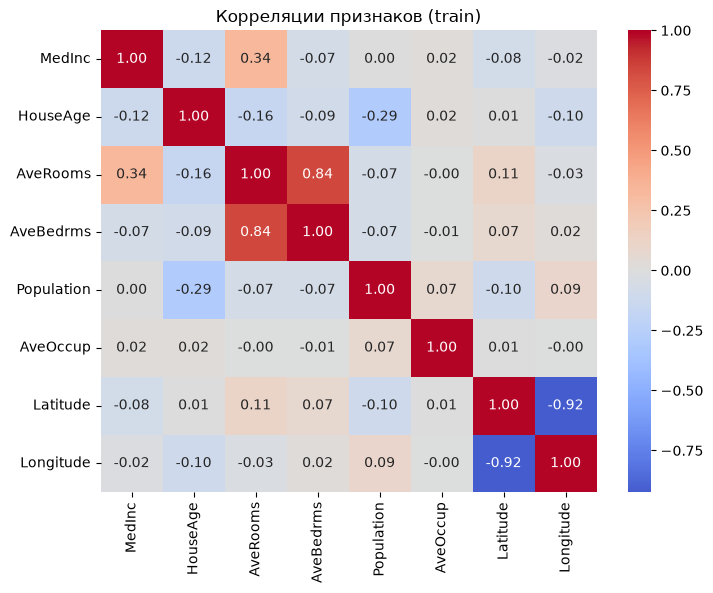

In [3]:
plt.figure(figsize=(8,6))
sns.heatmap(X_train.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Корреляции признаков (train)")
plt.show()

In [4]:
def calc_vif(X_):
    Xs = (X_ - X_.mean()) / X_.std()
    Xs = Xs.assign(const=1)
    return pd.Series(
        [variance_inflation_factor(Xs.values, i) for i in range(Xs.shape[1]-1)],
        index=X_.columns, name="VIF").sort_values(ascending=False)

calc_vif(X_train)

Latitude      9.206134
Longitude     8.875984
AveRooms      7.917240
AveBedrms     6.609200
MedInc        2.539815
HouseAge      1.237337
Population    1.134824
AveOccup      1.009733
Name: VIF, dtype: float64

In [5]:
cols = all_cols.copy()
while True:
    vif = calc_vif(X_train[cols])
    if vif.iloc[0] <= 5: break
    print(f"Удаляем {vif.index[0]} (VIF={vif.iloc[0]:.1f})")
    cols.remove(vif.index[0])
reduced_cols = cols
print(reduced_cols)

Удаляем Latitude (VIF=9.2)
Удаляем AveRooms (VIF=7.2)
['MedInc', 'HouseAge', 'AveBedrms', 'Population', 'AveOccup', 'Longitude']


In [6]:
pipe_red = make_pipe()
res_red = evaluate(pipe_red, reduced_cols, "Сокращённая")
comparison = pd.concat([res_base, res_red], axis=1).T.round(4)
comparison

,MAE_train,RMSE_train,R2_train,MAE_test,RMSE_test,R2_test
Базовая (все признаки),0.5286,0.7197,0.6126,0.5332,0.7456,0.5758
Сокращённая,0.6000,0.8042,0.5162,0.6031,0.8127,0.4960


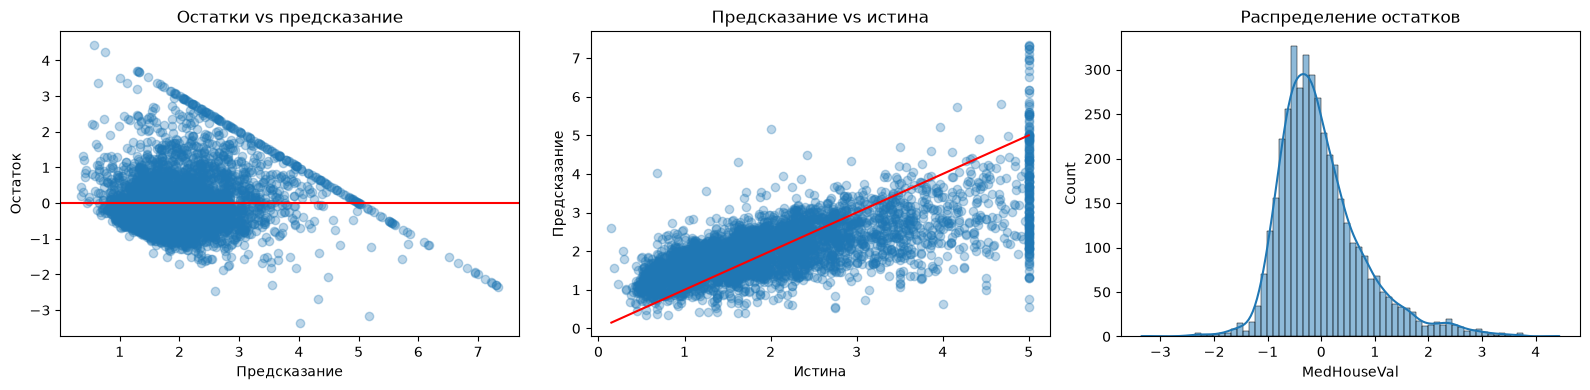

In [7]:
pred = pipe_red.predict(X_test[reduced_cols])
resid = y_test - pred

fig, ax = plt.subplots(1, 3, figsize=(16,4))
ax[0].scatter(pred, resid, alpha=.3); ax[0].axhline(0, color="r")
ax[0].set(xlabel="Предсказание", ylabel="Остаток", title="Остатки vs предсказание")

ax[1].scatter(y_test, pred, alpha=.3)
lim = [y_test.min(), y_test.max()]
ax[1].plot(lim, lim, "r"); ax[1].set(xlabel="Истина", ylabel="Предсказание", title="Предсказание vs истина")

sns.histplot(resid, kde=True, ax=ax[2]); ax[2].set_title("Распределение остатков")
plt.tight_layout(); plt.show()

Text(0.5, 1.0, 'Коэффициенты (на стандартизованных признаках)')

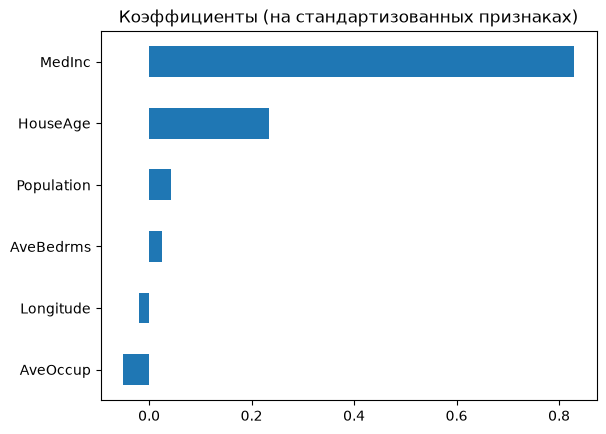

In [8]:
coefs = pd.Series(pipe_red.named_steps["model"].coef_, index=reduced_cols)
coefs.sort_values().plot.barh(); plt.title("Коэффициенты (на стандартизованных признаках)")

In [9]:
cols_v2 = [c for c in all_cols if c != "AveBedrms"]
res_v2 = evaluate(make_pipe(), cols_v2, "Без AveBedrms (v2)")
comparison = pd.concat([res_base, res_red, res_v2], axis=1).T.round(4)
comparison

,MAE_train,RMSE_train,R2_train,MAE_test,RMSE_test,R2_test
Базовая (все признаки),0.5286,0.7197,0.6126,0.5332,0.7456,0.5758
Сокращённая,0.6000,0.8042,0.5162,0.6031,0.8127,0.4960
Без AveBedrms (v2),0.5426,0.7317,0.5995,0.5425,0.7398,0.5823


Мультиколлинеарность. Пары с |r| > 0.8: AveRooms–AveBedrms (0.84), Latitude–Longitude (−0.92). VIF > 5: Latitude (9.2), Longitude (8.9), AveRooms (7.9), AveBedrms (6.6).

Сравнение. Автоматическое удаление по VIF (Latitude, AveRooms) ухудшило test-MAE с 0.533 до 0.603, то есть ошибка выросла примерно на $7 000, R² упал с 0.576 до 0.496. Широта несёт географическую информацию, поэтому высокий VIF не означает её избыточность.

Остатки. Виден диагональный «потолок» из-за обрезки цены на $500 000, разброс растёт с ростом предсказания, а дорогие дома недооцениваются. Допущения линейной модели выполняются не полностью.

Решение. Финальный набор: все признаки, кроме AveBedrms (7 признаков). Модель без AveBedrms по качеству не уступает базовой (test R² 0.582 против 0.576, RMSE 0.740 против 0.746, то есть ≈ $74 000 против ≈ $74 600), хотя MAE чуть выше (0.543 против 0.533, разница ≈ $900). Это означает, что AveBedrms дублировал AveRooms (r = 0.84) и его можно убрать без потери качества. Высокий VIF у Latitude и Longitude обусловлен геометрией Калифорнии, а не дублированием информации: их удаление ухудшило MAE примерно на $7 000, поэтому оба признака оставлены. R² на train и test близки (0.600 и 0.582), переобучения нет. Остатки показывают нарушение допущений линейной модели (обрезка цены на $500 000, рост разброса), поэтому дальше стоит попробовать логарифм цены, исключение обрезанных наблюдений или нелинейные модели.

In [10]:
pipe_final = make_pipe()
pipe_final.fit(X_train[cols_v2], y_train)
pred = pipe_final.predict(X_test[cols_v2])
resid = y_test - pred

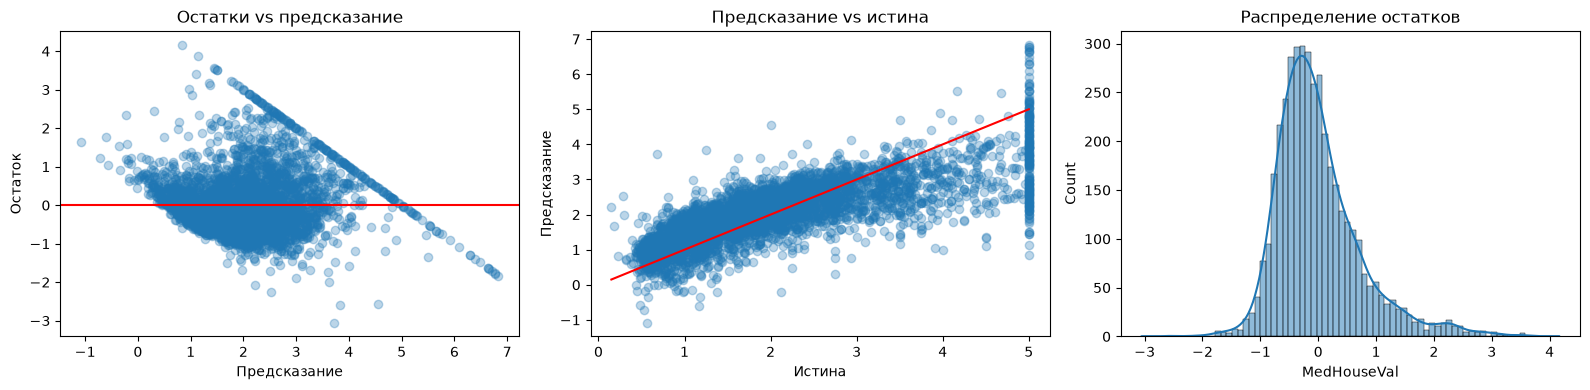

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(pred, resid, alpha=.3); ax[0].axhline(0, color="r")
ax[0].set(xlabel="Предсказание", ylabel="Остаток", title="Остатки vs предсказание")

ax[1].scatter(y_test, pred, alpha=.3)
lim = [y_test.min(), y_test.max()]
ax[1].plot(lim, lim, "r")
ax[1].set(xlabel="Истина", ylabel="Предсказание", title="Предсказание vs истина")

sns.histplot(resid, kde=True, ax=ax[2]); ax[2].set_title("Распределение остатков")
plt.tight_layout(); plt.show()

MAE 0.543 означает, что модель в среднем ошибается на ≈ $54 300. RMSE 0.740 (≈ $74 000) больше MAE, потому что сильнее штрафует крупные ошибки. R² 0.582 означает, что модель объясняет около 58 % дисперсии цены на тестовой выборке.